## Projeto 01 - Revisão Probabilidade e Teoria de Decisão Bayesiana

### Capítulo 1 do relatório - Apresentação do Problema e Contextualização dos dados. 

A primeira etapa consiste na escolha de um conjunto de dados público, ou seja, que permita a replicação e análise. A única restrição é que seja um dataset de 'Classification", i.e., que contenha rótulos nas classes. 

Escolhido o dataset, a primeira atividade consiste em escrever uma introdução descrevendo o trabalho original que disponibilizou o dataset, contextualizando a origem, a utilidade e a descrição de como o dataset foi usado pelos autores (domínio da aplicação) e, se possível, quais foram os resultados obtidos para comparação posterior.

Em seguida, descreva o dataset e suas propriedades, tais como o que representa, tipo de dados, características, amostras, etc.

## Dataset escolhido: Breast cancer Wisconsin (diagnostic) dataset

Creators: Dr. William H. Wolberg, W. Nick Street, Olvi L. Mangasarian
Donor: Nick Street
Date: November, 1995

Resumo que descreve o dataset: 

Técnicas interativas de processamento de imagens, juntamente com um classificador indutivo baseado em programação linear, foram utilizadas para criar um sistema altamente preciso para o diagnóstico de tumores de mama. Uma pequena fração de uma lâmina de aspirado por agulha fina é selecionada e digitalizada. Por meio de uma interface interativa, o usuário inicializa modelos de contorno ativo, conhecidos como snakes (serpentes), próximos às bordas de um conjunto de núcleos celulares. As snakes personalizadas são deformadas até atingirem o formato exato dos núcleos. Isso permite uma análise precisa e automatizada do tamanho, formato e textura nuclear. Dez dessas características são computadas para cada núcleo, e o valor médio, o maior (ou "pior") valor e o erro padrão de cada característica são encontrados ao longo do intervalo de células isoladas.

Após 569 imagens terem sido analisadas dessa forma, diferentes combinações de características foram testadas para encontrar aquelas que melhor separam as amostras benignas das malignas. Uma precisão de validação cruzada de dez fatores (10-fold) de 97% foi alcançada utilizando um único plano de separação em três das trinta características: textura média, pior área e pior suavidade. Isso representa uma melhoria em relação aos melhores resultados de diagnóstico na literatura médica. O sistema está atualmente em uso nos Hospitais da Universidade de Wisconsin. O mesmo conjunto de características também foi utilizado na tarefa muito mais difícil de prever a recorrência distante de malignidade em pacientes, resultando em uma precisão de 86%.

## Descrição do dataset: 

Número de Instâncias: *569*

Número de Atributos: *30 atributos preditivos numéricos e a classe*

Informações dos Atributos:

* Raio (média das distâncias do centro aos pontos do perímetro)
* Textura (desvio padrão dos valores de escala de cinza)
* Perímetro
* Área
* Suavidade (variação local nos comprimentos dos raios)
* Compacidade (perímetro² / área - 1.0)
* Concavidade (gravidade das porções côncavas do contorno)
* Pontos côncavos (número de porções côncavas do contorno)
* Simetria
* Dimensão fractal ("aproximação da linha de costa" - 1)

A média, o erro padrão e o "pior" ou maior valor (média dos três piores/maiores valores) dessas características foram computados para cada imagem, resultando em 30 características. Por exemplo, o campo 0 é o Raio Médio, o campo 10 é o Erro Padrão do Raio e o campo 20 é o Pior Raio.

* Classes:
    * WDBC-Maligno
    * WDBC-Benigno

Valores de Atributos Ausentes: Nenhum

Distribuição das Classes:

* 212 - Maligno, 357 - Benigno

## Análise exploratória
### Capítulo 2 do relatório - Teoria de Decisão Bayesiana

Com o propósito de aplicar a teoria de decisão bayesiana ao conjunto de dados escolhido, inicialmente construa a matriz de distribuição de frequências (dados) e, a partir dessa matriz, defina os seguintes itens:
* 2.1 - Formalize o espaço amostral;
* 2.2 - A probabilidade de cada resultado possível (probabilidades a priori);
* 2.3 - Defina pelo menos 3 eventos e calcule a probabilidade de cada um dos eventos;
* 2.4 - Descrever/Comente como a escolha das características (eventos) diferentes modificou (ou não) os resultados;
* 2.5 - Defina pelo menos um exemplo de união de probabilidades;
* 2.6 - Defina pelo menos um exemplo de interseção de probabilidades;
* 2.7 - Defina pelo menos 3 exemplos de probabilidades condicionais.
* 2.8 - Considerando as amostras do conjunto de dados e crie partições (discretizações, como histogramas por exemplo) para a construção das curvas de FDP e da Probabilidade a Posteriori.
* 2.9 - Aplique a Função de Densidade e Probabilidade (FDP) condicional como visto em aula para as pelo menos 2 características, considerando as classes do conjunto de dados adotado, gerando os respectivos gráficos.
* 2.10 - Aplicar a regra de decisão bayesiana (probabilidade a posteriori) como visto em aula para pelo menos 2 características, considerando as classes do conjunto de dados, gerando os respectivos gráficos.
* 2.11 - Descrever como a escolha das características (eventos) diferentes modificou (ou não) os resultados das curvas de probabilidades. Inclua os resultados como seção adicional do relatório do exercício anterior, como uma forma de prosseguimento do que já foi realizado.

In [ ]:
# Imports e setup inicial
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from plotnine import (
    aes,
    after_stat,
    geom_boxplot,
    geom_density,
    geom_histogram,
    geom_hline,
    geom_jitter,
    geom_line,
    geom_point,
    ggplot,
    ggtitle,
    theme_bw,
)
from scipy import stats
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

breast_cancer_data = load_breast_cancer(as_frame=True)
df = breast_cancer_data.frame
total_samples = len(df)

In [149]:
# Mapeando nomes e targets
df['target_name'] = df['target'].map({0: 'Malignant', 1: 'Benign'})

# Subset de Features que vamos explorar
main_features = ['mean radius', 'mean texture', 'mean perimeter', 'mean area'] 

# Resumo numerico
df[main_features].describe()

,mean radius,mean texture,mean perimeter,mean area
count,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104
std,3.524049,4.301036,24.298981,351.914129
min,6.981000,9.710000,43.790000,143.500000
25%,11.700000,16.170000,75.170000,420.300000
50%,13.370000,18.840000,86.240000,551.100000
75%,15.780000,21.800000,104.100000,782.700000
max,28.110000,39.280000,188.500000,2501.000000


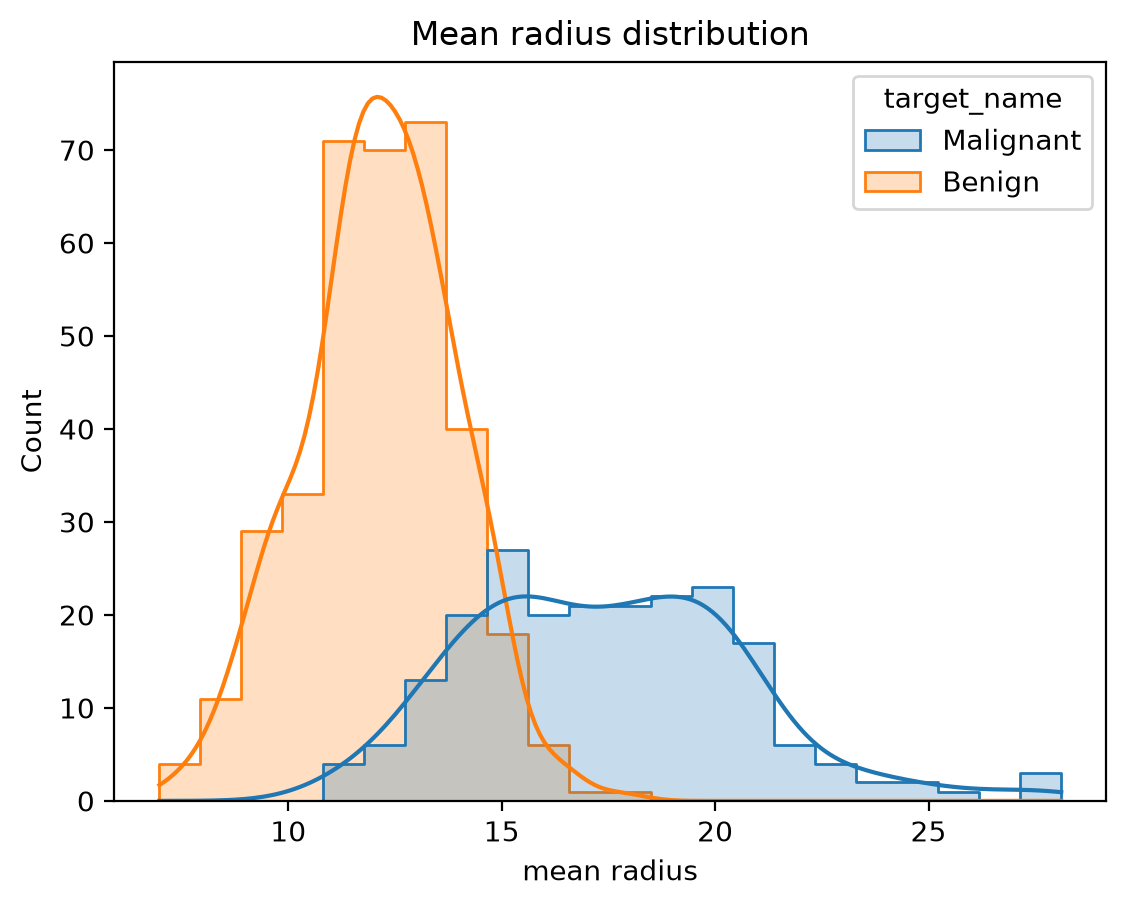

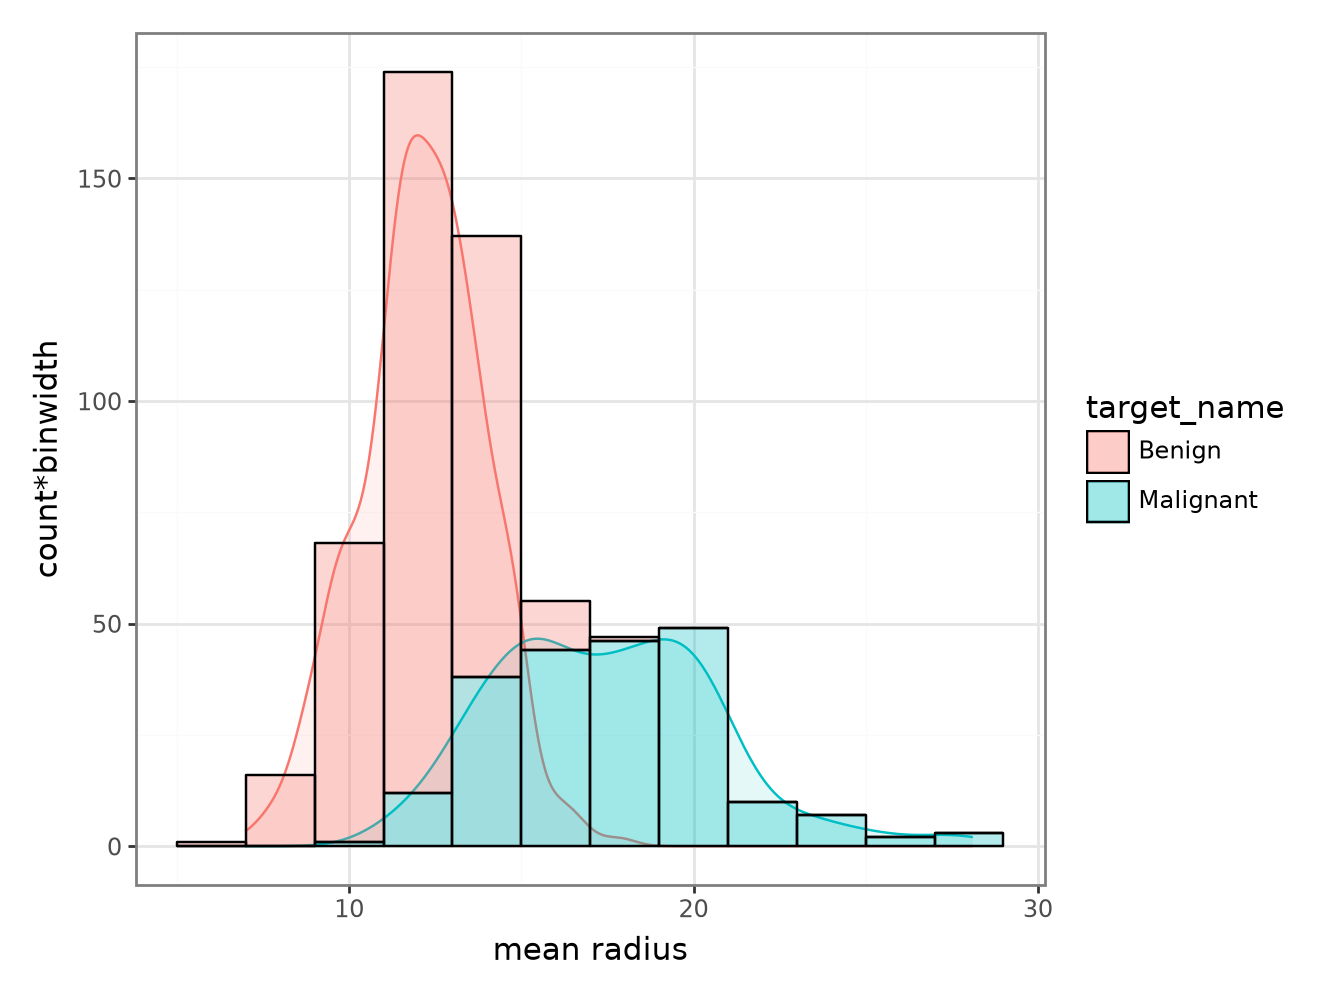

In [150]:
# DataViz: histograma com seaborn
sns.histplot(
    data=df, x = "mean radius", hue="target_name", kde=True, element="step"
)
plt.title("Mean radius distribution")

# DataViz: histograma com plotnine (ggplot2 em Python)
binwidth = 2

(ggplot(df, aes(x= 'mean radius', fill = 'target_name', color = 'target_name'))
+ geom_density(aes(y=after_stat('count*binwidth')), alpha = 0.1)
+ geom_histogram(aes(y=after_stat('count')), color = 'black', binwidth = binwidth, alpha = 0.3)
+theme_bw()
)

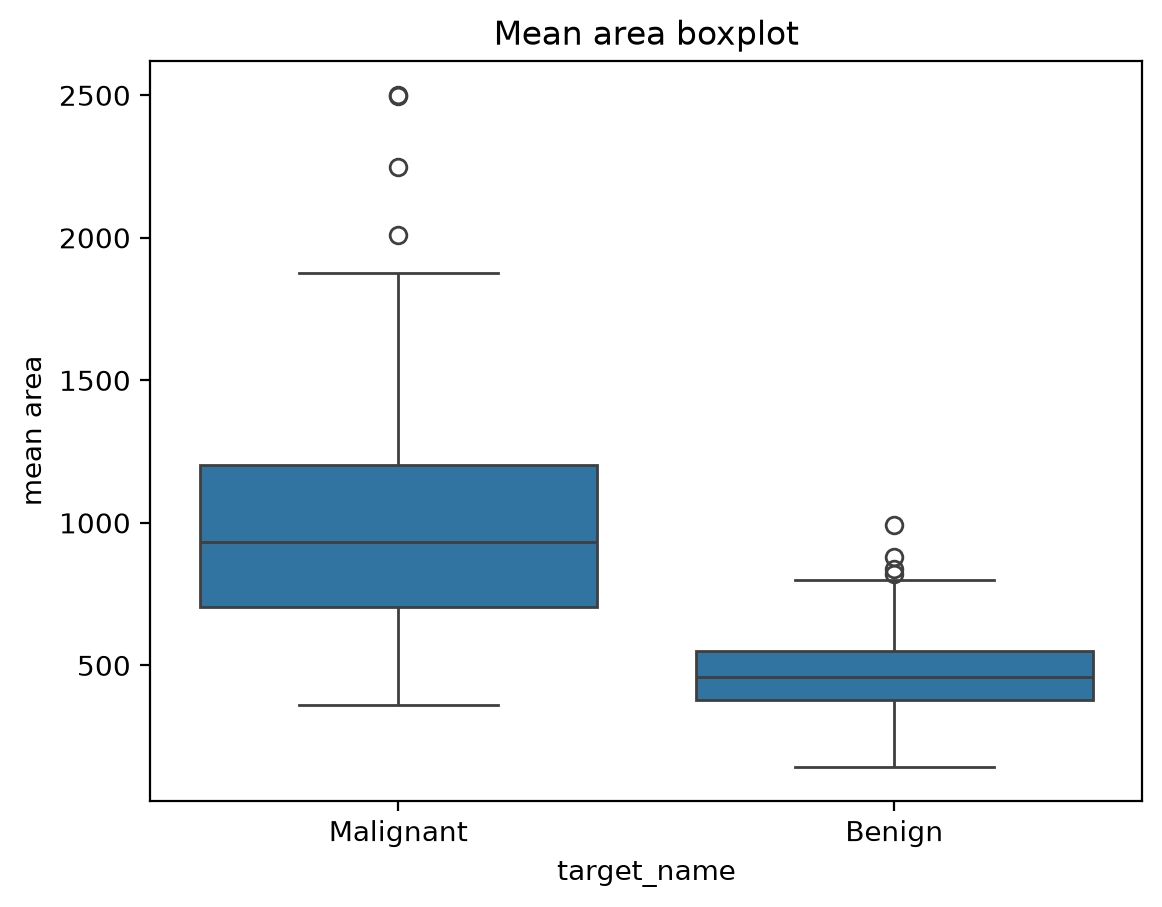

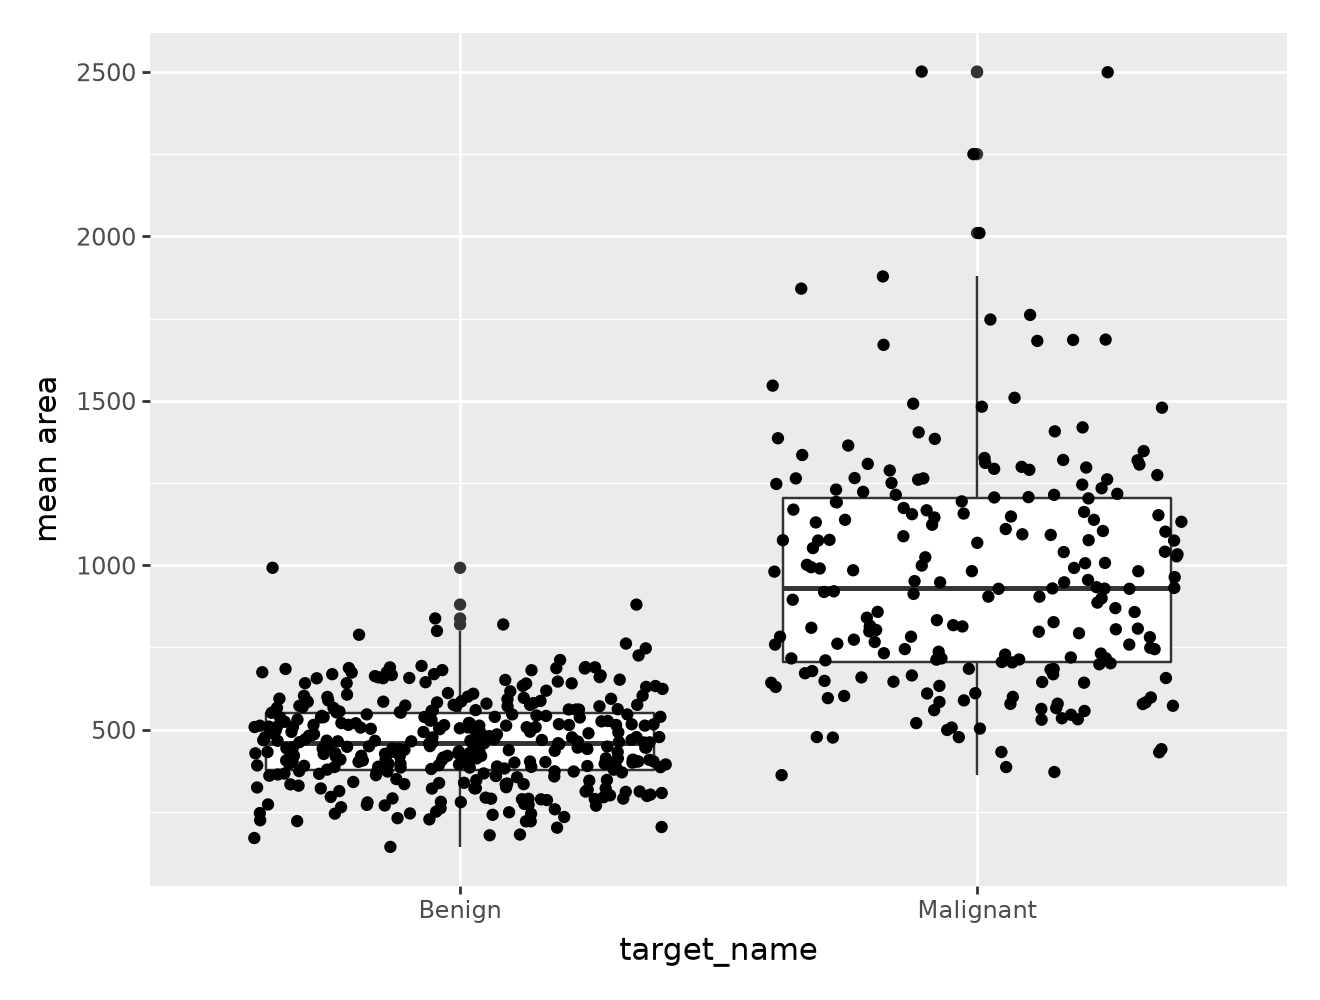

In [151]:
# DataViz: boxplot no seaborn
sns.boxplot(data=df, x="target_name", y="mean area")
plt.title('Mean area boxplot')

# DataViz: boxplot no plotnine
(
    ggplot(df, aes(x='target_name', y='mean area'))
    +geom_boxplot()
    +geom_jitter()
    )

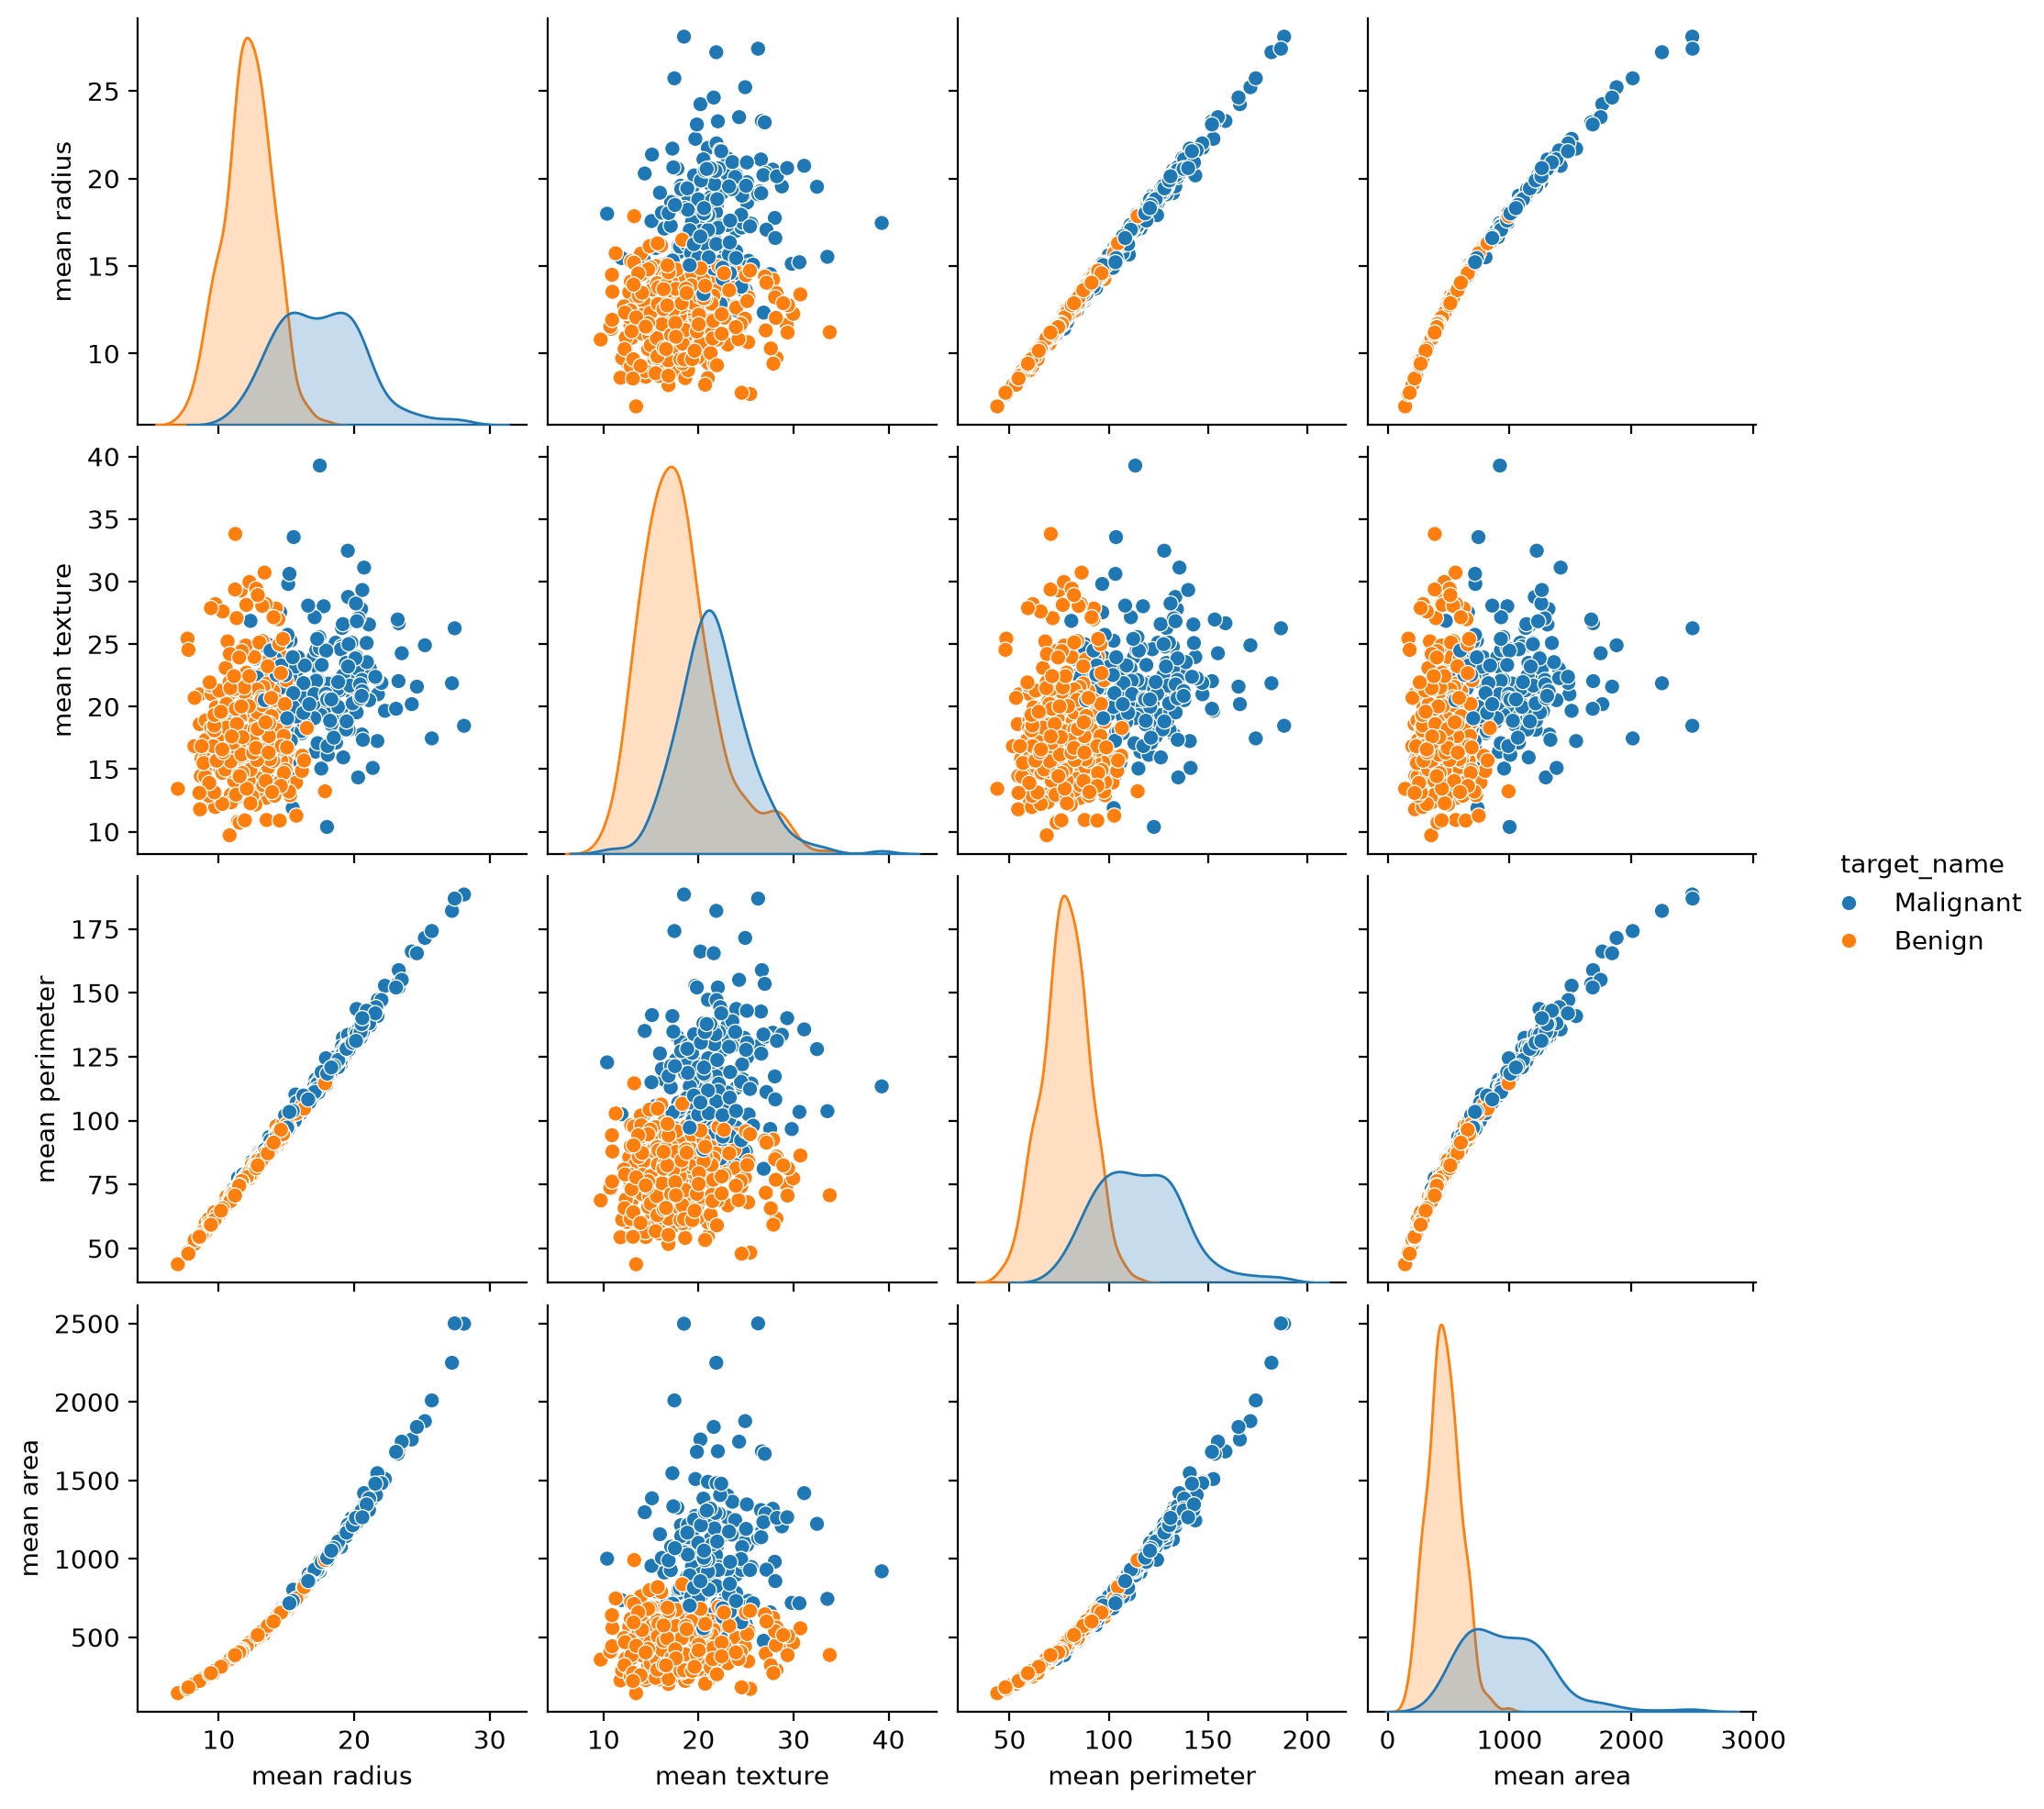

In [82]:
# DataViz: PairPlot
sns.pairplot(
    data=df[main_features + ['target_name']], hue="target_name"
)

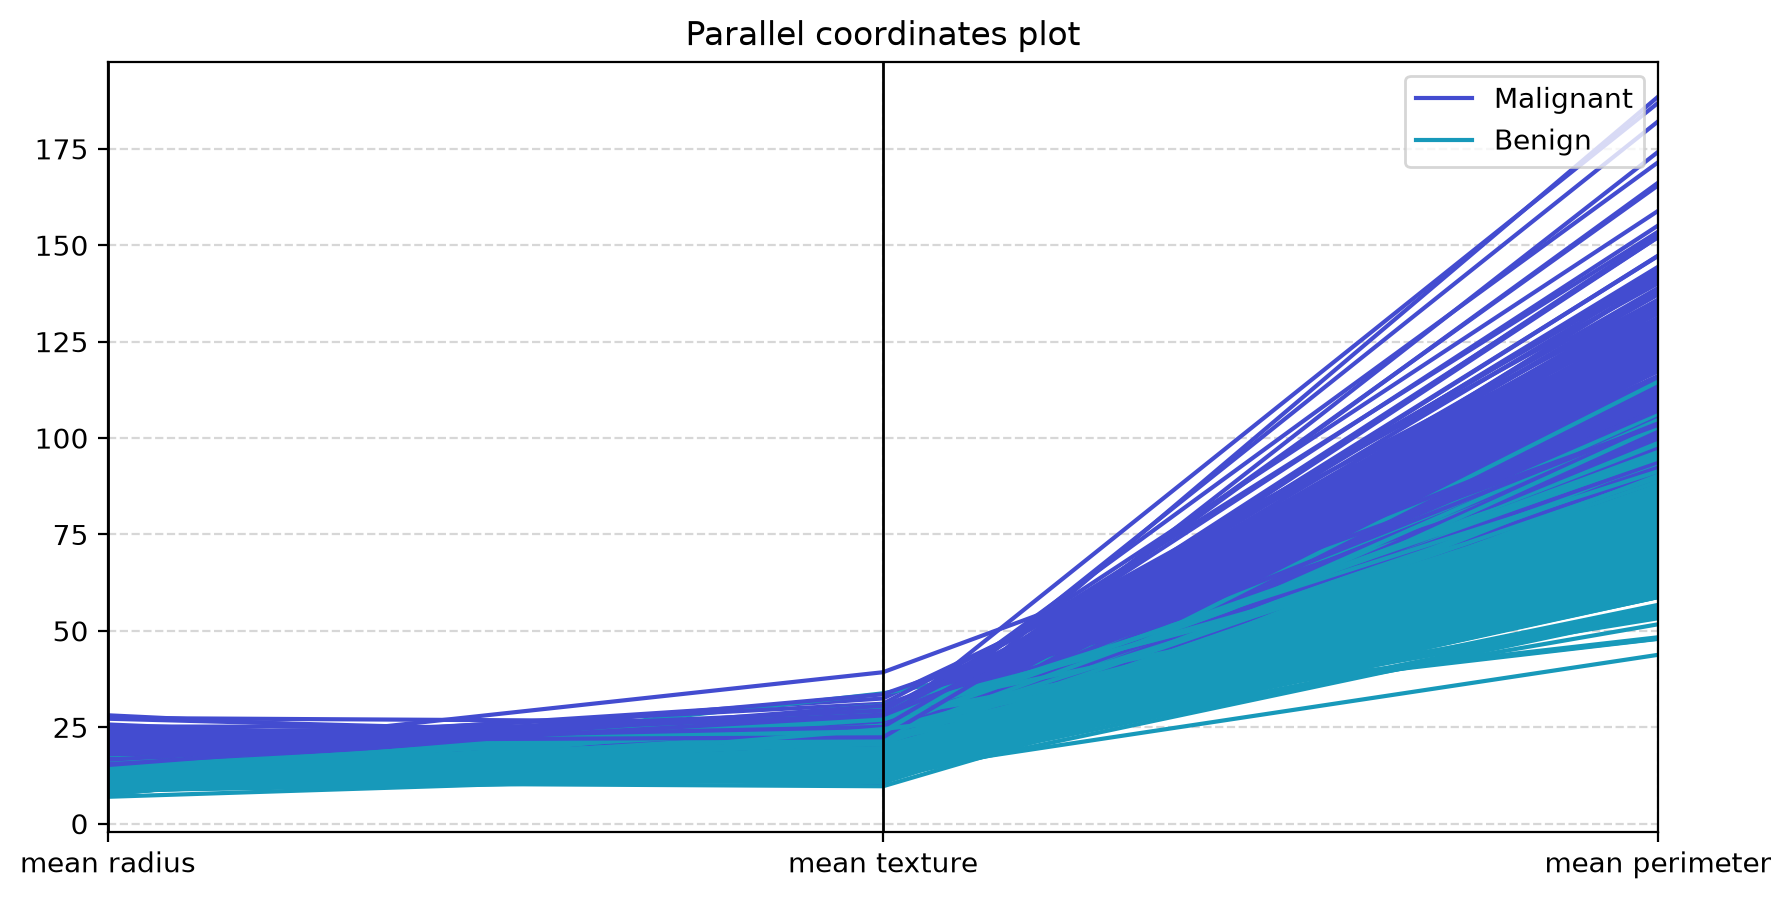

In [83]:
# DataViz: parallel coords
paralel_features = ['mean radius', 'mean texture', 'mean perimeter']

plt.figure(figsize=(10,5))
pd.plotting.parallel_coordinates(
    df[paralel_features + ['target_name']],
    class_column = "target_name"
)
plt.title('Parallel coordinates plot')
plt.grid(True, linestyle = "--", alpha=0.5)
plt.show()


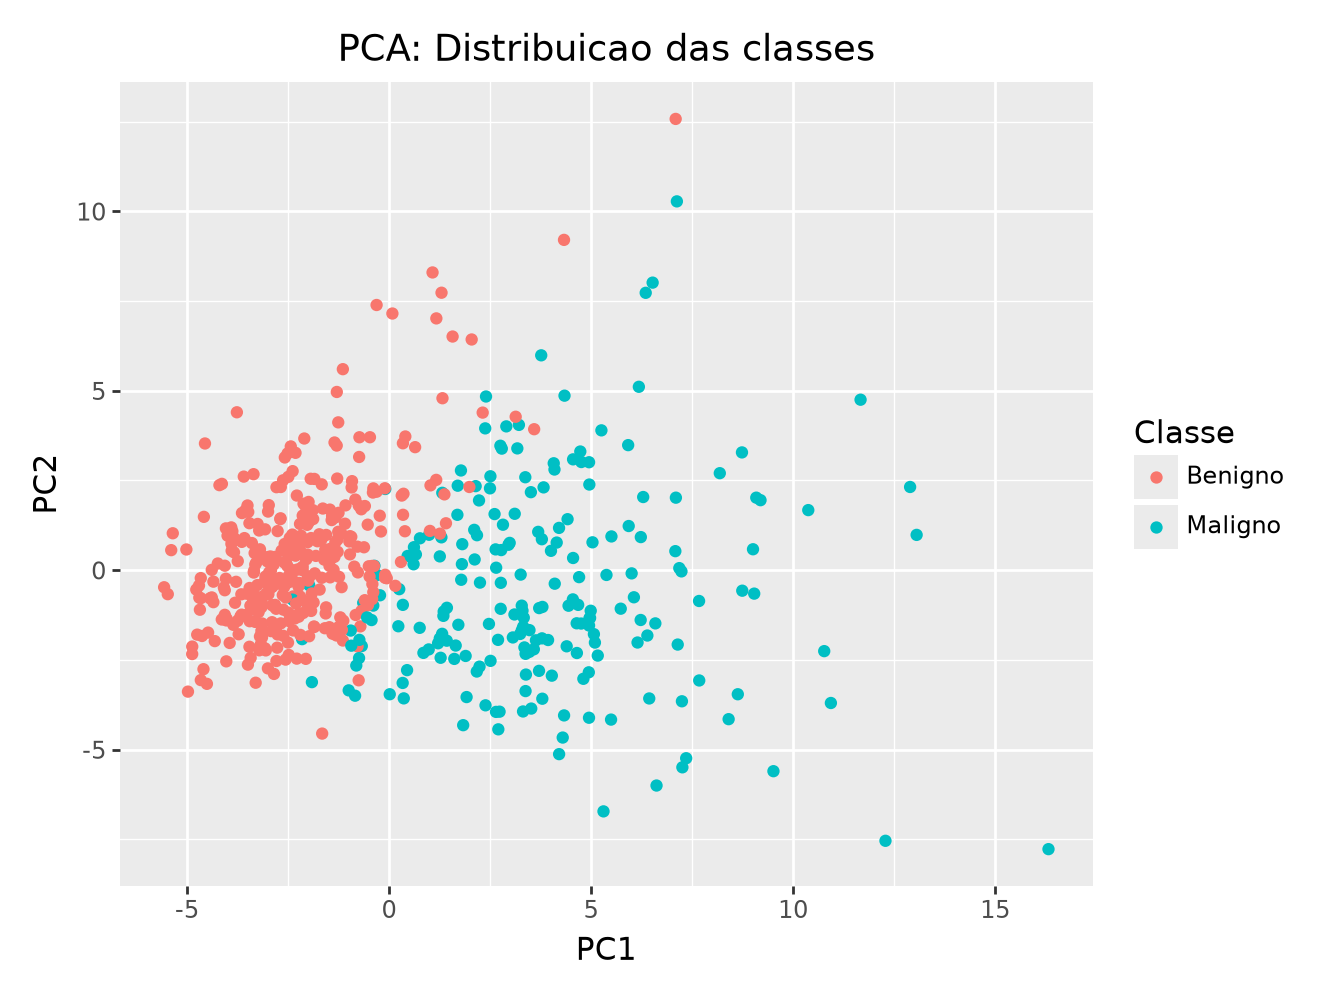

In [152]:
# Visualizando os dados com PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(breast_cancer_data.data)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

df_pca = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
df_pca['Classe'] = breast_cancer_data.target.map({0:'Maligno', 1:'Benigno'})

(
    ggplot(df_pca, (aes('PC1','PC2'))) 
    + geom_point(aes(color='Classe'))
    +ggtitle(title='PCA: Distribuicao das classes')
)
    

In [85]:
# Preparo para calcular probabilidades 
df_mal = df[df['target_name'] == 'Malignant']
df_ben = df[df['target_name'] == 'Benign']

mal_samples = len(df_mal)
ben_samples = len(df_ben)

In [86]:
# Resumo numerico por classe 
df_mal[main_features].describe()

,mean radius,mean texture,mean perimeter,mean area
count,212.000000,212.000000,212.000000,212.000000
mean,17.462830,21.604906,115.365377,978.376415
std,3.203971,3.779470,21.854653,367.937978
min,10.950000,10.380000,71.900000,361.600000
25%,15.075000,19.327500,98.745000,705.300000
50%,17.325000,21.460000,114.200000,932.000000
75%,19.590000,23.765000,129.925000,1203.750000
max,28.110000,39.280000,188.500000,2501.000000


In [87]:
# Resumo numerico por classe 
df_ben[main_features].describe()

,mean radius,mean texture,mean perimeter,mean area
count,357.000000,357.000000,357.000000,357.000000
mean,12.146524,17.914762,78.075406,462.790196
std,1.780512,3.995125,11.807438,134.287118
min,6.981000,9.710000,43.790000,143.500000
25%,11.080000,15.150000,70.870000,378.200000
50%,12.200000,17.390000,78.180000,458.400000
75%,13.370000,19.760000,86.100000,551.100000
max,17.850000,33.810000,114.600000,992.100000


In [94]:
# Probabilidades a priori
prior_mal = mal_samples / total_samples
prior_ben = ben_samples / total_samples
print(prior_mal, prior_ben, prior_ben+prior_mal)

0.37258347978910367 0.6274165202108963 1.0


In [95]:
# Calculando thresholds para definir eventos e suas probabilidades 
area_threshold = df['mean area'].mean()
texture_threshold = df['mean texture'].mean()
radius_threshold = df['mean radius'].mean()
print(area_threshold, texture_threshold, radius_threshold)

654.8891036906855 19.289648506151142 14.127291739894552


In [91]:
# Evento A: mean area > area threshold
eventA = len(df[df['mean area'] > area_threshold])
probA = eventA / total_samples
probA

0.3585237258347979

In [96]:
# Evento B:  mean texture > texture threshold
eventB = len(df[df['mean texture'] > texture_threshold])
probB = eventB / total_samples
print(probB)

0.46221441124780316


In [97]:
# Evento C: mean radius > radius threshold
eventC = len(df[df['mean radius'] > radius_threshold])
probC = eventC / total_samples
print(probC)

0.39718804920913886


In [98]:
# Evento D: mean area < area threshold AND mean texture > texture threshold
eventD = len(df[(df['mean area'] > area_threshold) & (df['mean texture'] > texture_threshold)])
probD = eventD / total_samples
print(probD)

0.24253075571177504


In [99]:
# Evento E: mean area > area threshold OR mean texture < texture threshold
eventE = len(df[(df['mean area'] > area_threshold) | (df['mean texture'] < texture_threshold)])
probE = eventE / total_samples
print(probE)

0.7803163444639719


In [101]:
# Conditional probability
# Evento F: IF A = mean area > area threshold AND B is Malignant

EventF = len(df[(df['mean area'] > area_threshold) & (df['target_name'] == 'Malignant')])  
probAB = EventF / total_samples

probcondAB = probAB / prior_mal
print(probcondAB)

0.8066037735849056


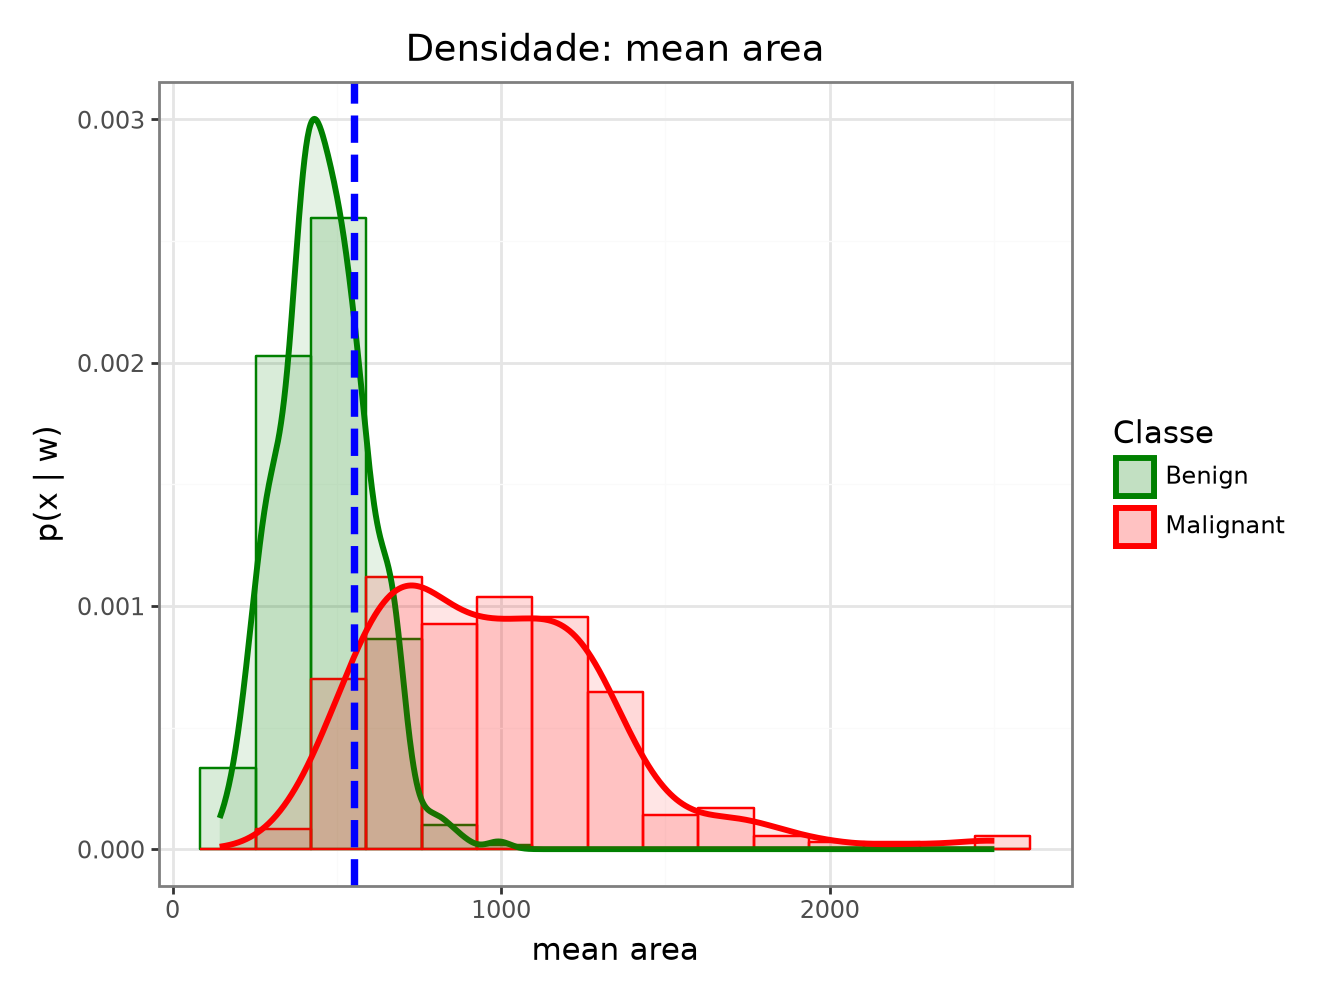

In [128]:
from plotnine import geom_vline, labs, scale_color_manual, scale_fill_manual


def plot_bayes(feature_name):
    ponto_decisivo = df[feature_name].median()

    plot = (
        ggplot(df, aes(x=feature_name, fill = "target_name", color = "target_name"))
    + geom_histogram(aes(y='stat(density)'), bins=15, alpha=0.15, position = "identity")
    + geom_density(size=1.2, alpha=0.1)
    + geom_vline(xintercept=ponto_decisivo, color = 'blue', linetype='dashed', size=1.5)
    + scale_fill_manual(values={'Malignant': 'red', 'Benign': 'green'})
        + scale_color_manual(values={'Malignant': 'red', 'Benign': 'green'})
        + labs(
            title=f"Densidade: {feature_name}",
            x=feature_name,
            y="p(x | w)",
            fill="Classe",
            color="Classe"
        )
        + theme_bw()
    )
    plot.show()

plot_bayes("mean area")

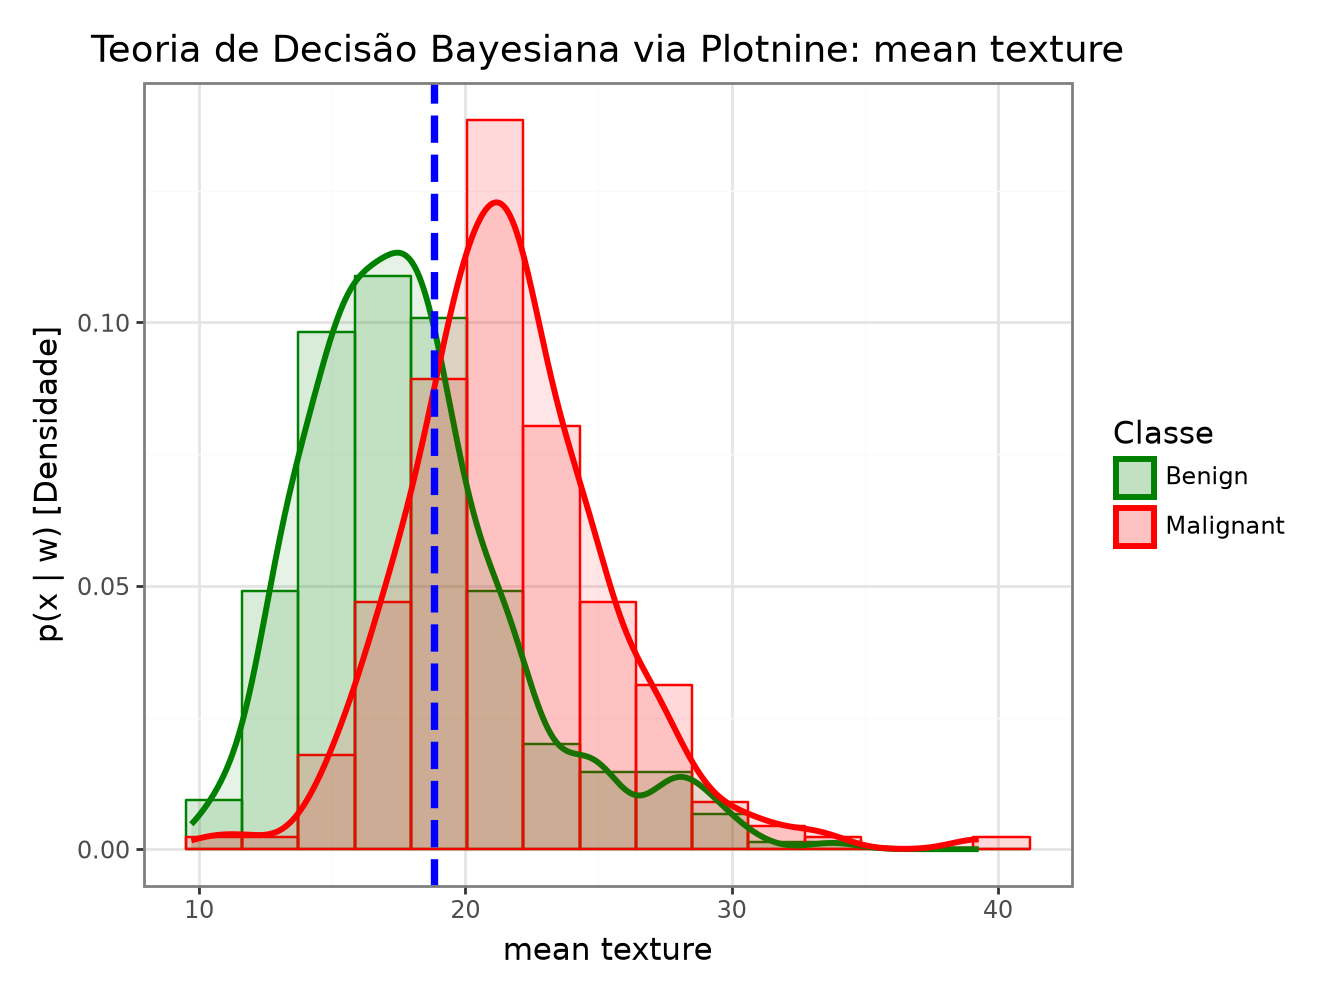

In [127]:
plot_bayes("mean texture")

In [136]:
def calcular_probabilidades_empiricas(df, feature_name, n_bins=10):
    #1. Priori das classes
    p_mal = (df['target_name'] == 'Malignant').mean()
    p_ben = (df['target_name'] == 'Benign').mean()

    #2. Discretizar a feature em bins
    df['bin'] = pd.cut(df[feature_name], bins=n_bins)

    #Tabela de contagens por bin e classe
    tabela = pd.crosstab(df['bin'], df['target_name'])

    #3. Verossimilhanca p(x in bin | omega): contagens no bin / total da classe
    # normalize columns divide cada coluna pela sua soma
    likelihood = pd.crosstab(df['bin'], df['target_name'], normalize='columns')
    likelihood.columns = ['p(x|Benign)', 'p(x|Malignant)']

    #4. Evidencia dos dados p(x in bin): proporcao de amostras por bin
    evidence = df['bin'].value_counts(normalize=True).sort_index()

    #5. Posteriori p(omega | x in bin):
    # p(omega|x) = [p(x|omega) p(omega)] / p(x)
    posterior_mal = (likelihood['p(x|Malignant)'] * p_mal) / evidence
    posterior_ben = (likelihood['p(x|Benign)'] * p_ben) / evidence

    # Resumo
    resultados = pd.DataFrame({
        'bin': likelihood.index.astype('str'),
        'p(x|Benign)': likelihood['p(x|Benign)'],
        'p(x|Malignant)': likelihood['p(x|Malignant)'],
        'p(x)': evidence,
        'p(Benign|x)': posterior_ben,
        'p(Malignant|x)': posterior_mal
    }).reset_index(drop=True)

    return resultados

In [137]:
tabela_bayes = calcular_probabilidades_empiricas(df, 'mean area', n_bins=10)
print(tabela_bayes[['bin', 'p(x|Malignant)', 'p(x)', 'p(Malignant|x)']])

                 bin  p(x|Malignant)      p(x)  p(Malignant|x)
0  (141.142, 379.25]        0.009434  0.163445        0.021505
1    (379.25, 615.0]        0.150943  0.441125        0.127490
2    (615.0, 850.75]        0.264151  0.177504        0.554455
3   (850.75, 1086.5]        0.212264  0.082601        0.957447
4  (1086.5, 1322.25]        0.240566  0.089631        1.000000
5  (1322.25, 1558.0]        0.066038  0.024605        1.000000
6  (1558.0, 1793.75]        0.028302  0.010545        1.000000
7  (1793.75, 2029.5]        0.014151  0.005272        1.000000
8  (2029.5, 2265.25]        0.004717  0.001757        1.000000
9  (2265.25, 2501.0]        0.009434  0.003515        1.000000


In [138]:
tabela_bayes2 = calcular_probabilidades_empiricas(df, 'mean texture')
print(tabela_bayes2[['bin', 'p(x|Malignant)', 'p(x)', 'p(Malignant|x)']])

                bin  p(x|Malignant)      p(x)  p(Malignant|x)
0    (9.68, 12.667]        0.009434  0.029877        0.117647
1  (12.667, 15.624]        0.028302  0.168717        0.062500
2  (15.624, 18.581]        0.146226  0.270650        0.201299
3  (18.581, 21.538]        0.330189  0.254833        0.482759
4  (21.538, 24.495]        0.292453  0.156415        0.696629
5  (24.495, 27.452]        0.132075  0.070299        0.700000
6  (27.452, 30.409]        0.037736  0.036907        0.380952
7  (30.409, 33.366]        0.014151  0.007030        0.750000
8  (33.366, 36.323]        0.004717  0.003515        0.500000
9   (36.323, 39.28]        0.004717  0.001757        1.000000


In [156]:
def plot_posterior_empirica(df, feature_name, n_bins=10):
    tabela = calcular_probabilidades_empiricas(df, feature_name, n_bins)

    # Converte pra formato longo
    df_long = pd.melt(
        tabela,
        id_vars=['bin'],
        value_vars=['p(Benign|x)', 'p(Malignant|x)'],
        var_name='Classe',
        value_name='Posteriori'
    )
    
    df_long['Classe'] = df_long['Classe'].map({
        'p(Benign|x)': 'Benign', 'p(Malignant|x)':'Malignant'
    })
    df_long['bin'] = pd.Categorical(
        df_long['bin'], categories=tabela['bin'].tolist(), ordered=True
    )

    return (
        ggplot(df_long,
        aes(x='bin', y='Posteriori', color='Classe', group='Classe'),
        )
        + geom_line(size=1)
        + geom_point(size=2.5)
        + geom_hline(yintercept=0.5, linetype='dashed', color='blue')
        + scale_color_manual(values={'Benign':'green', 'Malignant':'red'})
        + labs(
            title=f'Posteriori Empirica: {feature_name}',
            x=f'Intervalos de {feature_name}',
            y='P(omega|x)'
        )
        +theme_bw()
    )

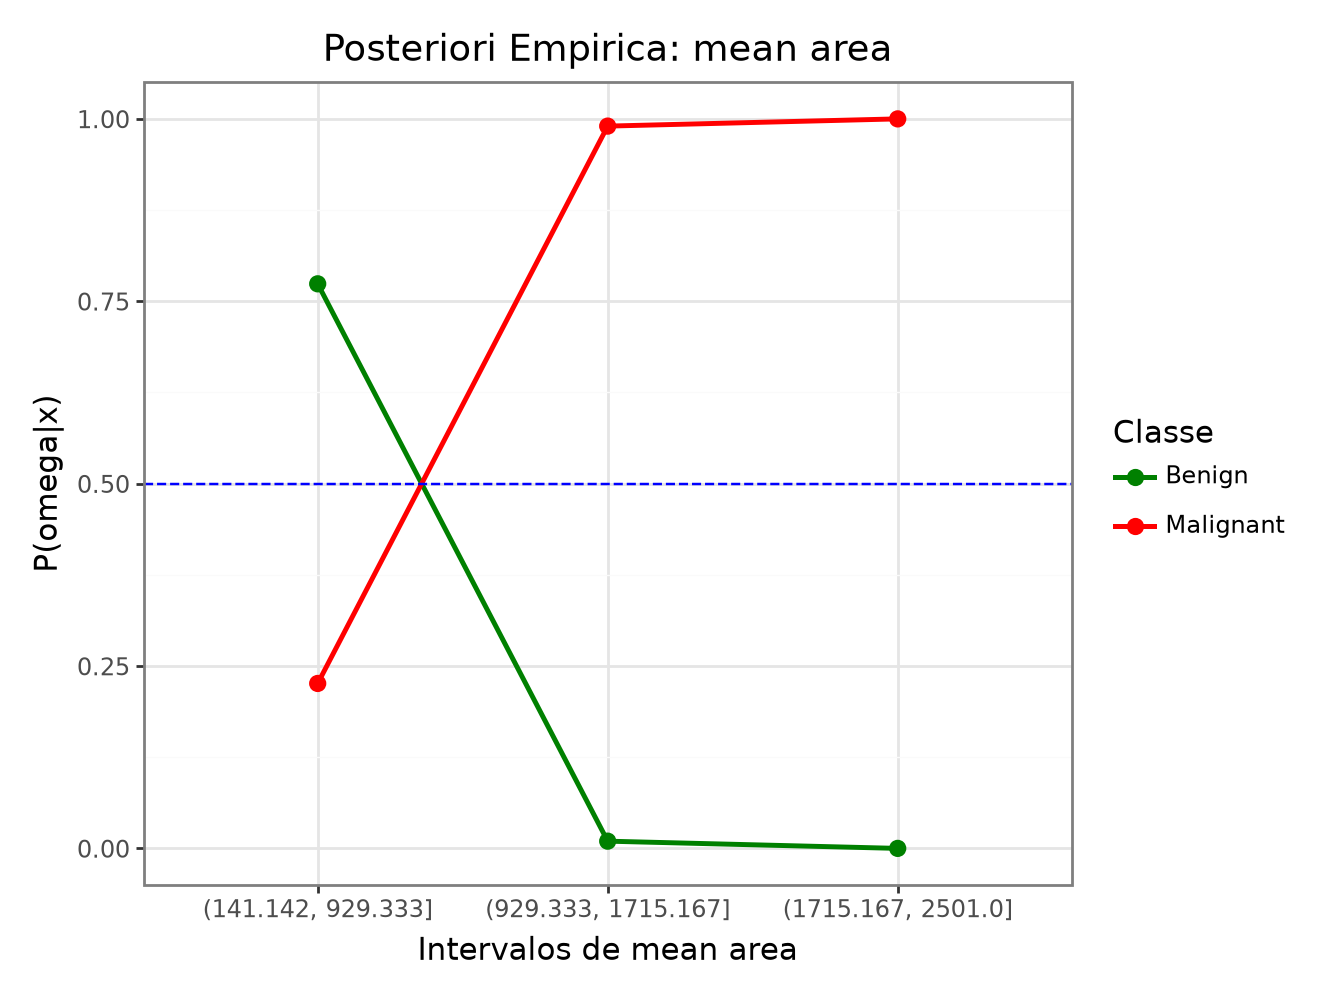

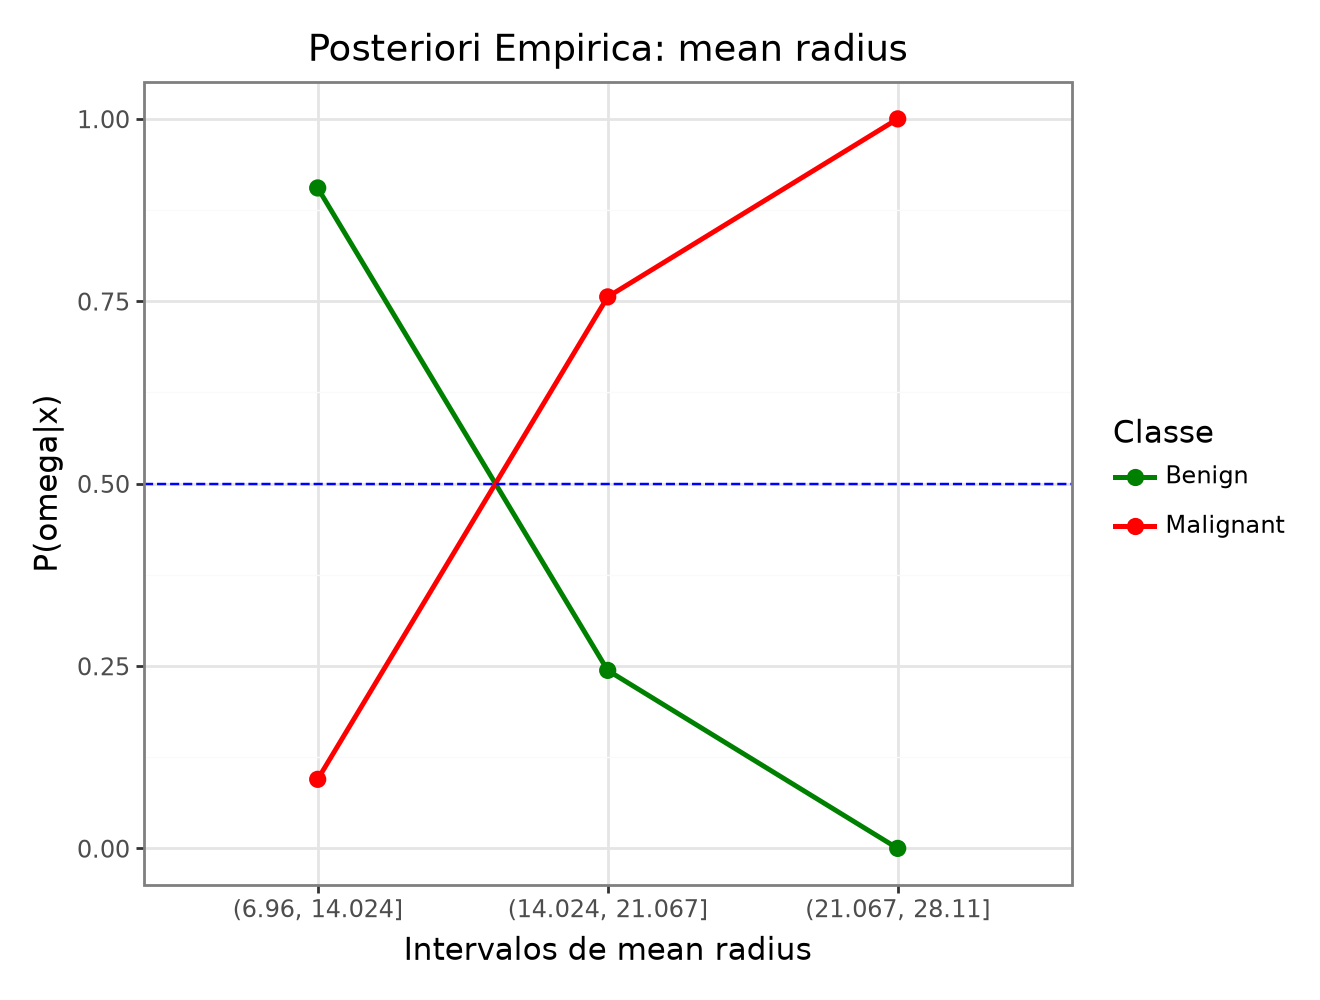

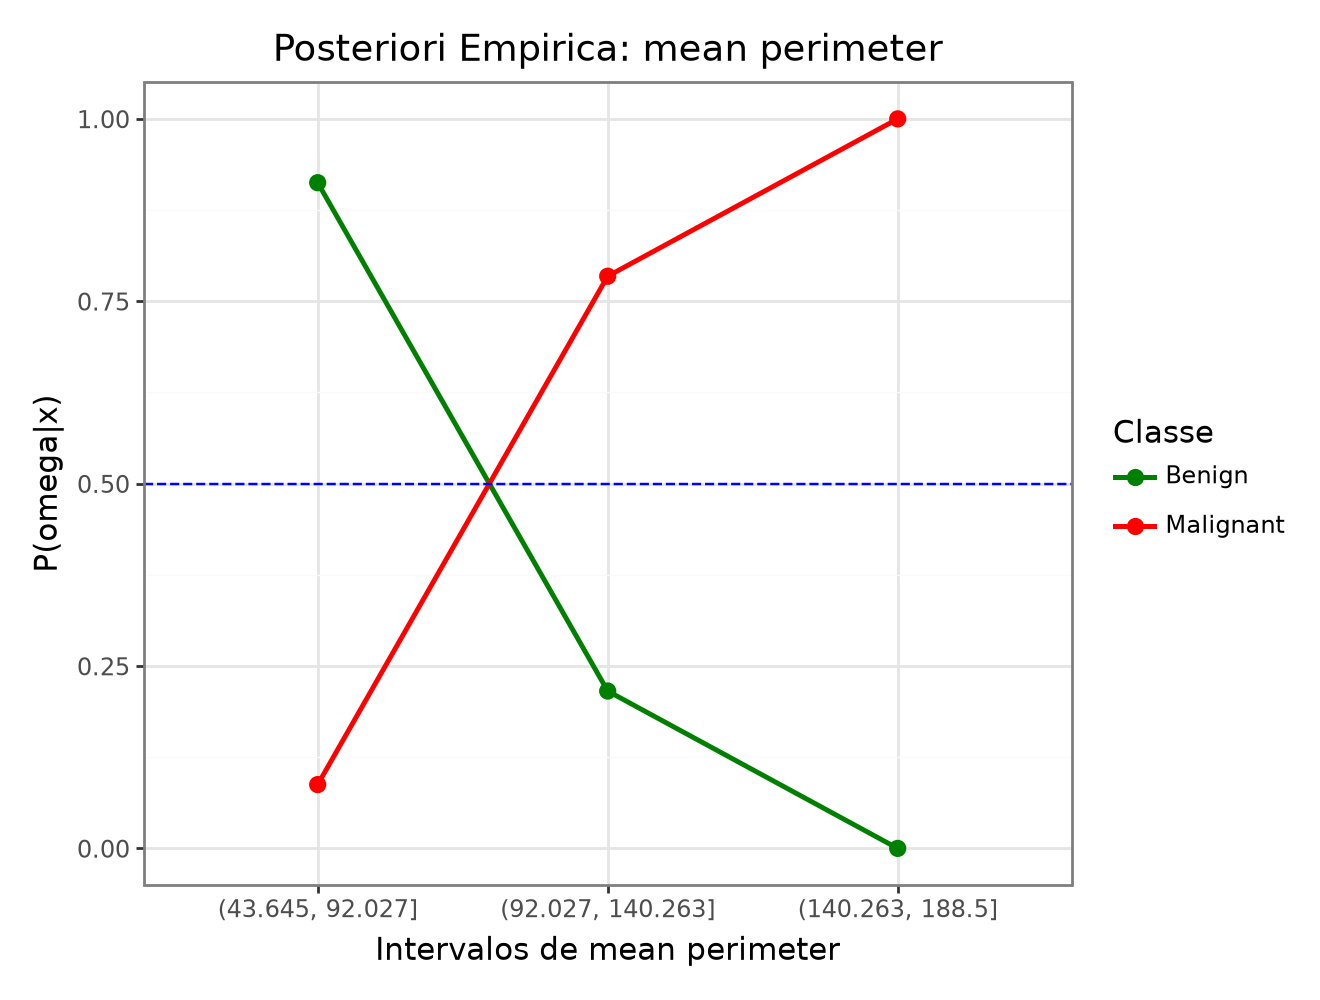

In [164]:
# Exemplo 1: mean area
p1 = plot_posterior_empirica(df, 'mean area', n_bins=3)
p1.show()

# Exemplo 2: mean radius
p2 = plot_posterior_empirica(df, 'mean radius', n_bins=3)
p2.show()

# Exemplo 3: mean texture
p3 = plot_posterior_empirica(df, 'mean perimeter', n_bins=3)
p3.show()